In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

FILE = "reviews.csv"
TEXT_COL = "review"
RATING_COL = "rating"

df = pd.read_csv(FILE).dropna(subset=[TEXT_COL]).copy()
df[TEXT_COL] = df[TEXT_COL].astype(str)
df["review_length"] = df[TEXT_COL].str.split().str.len()
sns.set_theme(style="whitegrid")
df.head()

,review_id,review,rating,review_length
0,1,"Amazing product, works perfectly!",5,4
1,2,"Terrible quality, broke in a day.",1,6
2,3,"It is okay, nothing special.",3,5
3,4,"Love it, totally worth the price!",5,6
4,5,"Worst purchase ever, waste of money.",1,6


## Chart 1: Bar chart - how many reviews per rating?

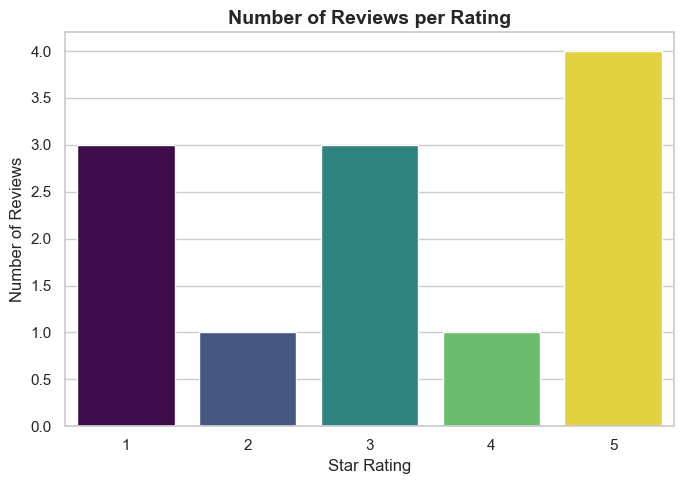

In [3]:
plt.figure(figsize=(7, 5))
sns.countplot(x=RATING_COL, data=df, hue=RATING_COL, palette="viridis", legend=False)
plt.title("Number of Reviews per Rating", fontsize=14, fontweight="bold")
plt.xlabel("Star Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.savefig("chart1_ratings.png", dpi=150)
plt.show()

## Chart 2: Pie chart - share of each rating

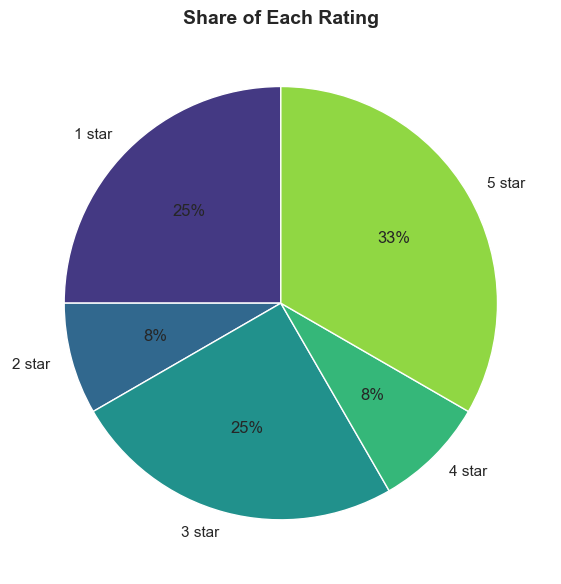

In [4]:
counts = df[RATING_COL].value_counts().sort_index()
plt.figure(figsize=(6, 6))
plt.pie(counts, labels=[f"{r} star" for r in counts.index], autopct="%1.0f%%",
        startangle=90, colors=sns.color_palette("viridis", len(counts)))
plt.title("Share of Each Rating", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("chart2_pie.png", dpi=150)
plt.show()

## Chart 3: Histogram - how long are the reviews?

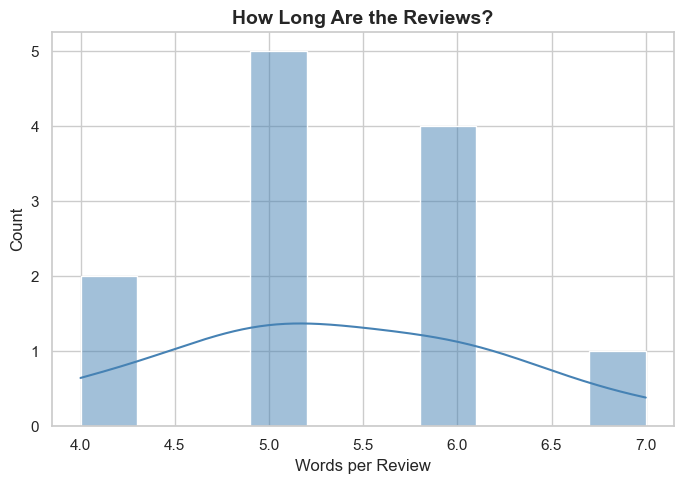

In [5]:
plt.figure(figsize=(7, 5))
sns.histplot(df["review_length"], bins=10, kde=True, color="steelblue")
plt.title("How Long Are the Reviews?", fontsize=14, fontweight="bold")
plt.xlabel("Words per Review")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("chart3_length.png", dpi=150)
plt.show()

## Chart 4: Box plot - review length by rating

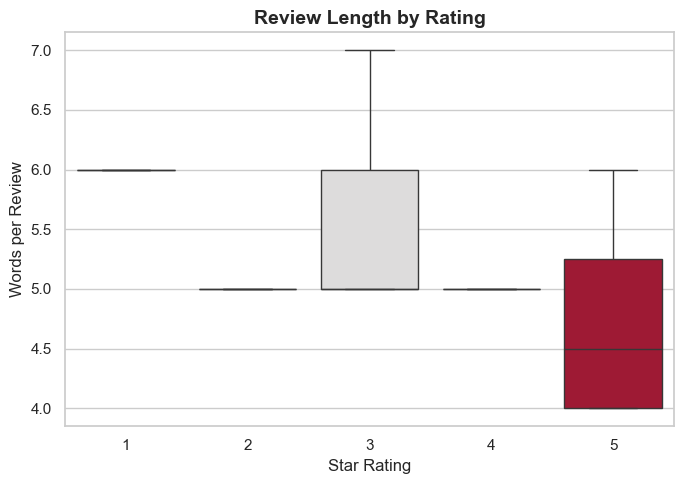

In [6]:
plt.figure(figsize=(7, 5))
sns.boxplot(x=RATING_COL, y="review_length", data=df, hue=RATING_COL, palette="coolwarm", legend=False)
plt.title("Review Length by Rating", fontsize=14, fontweight="bold")
plt.xlabel("Star Rating")
plt.ylabel("Words per Review")
plt.tight_layout()
plt.savefig("chart4_boxplot.png", dpi=150)
plt.show()

## Chart 5: Heatmap - correlation

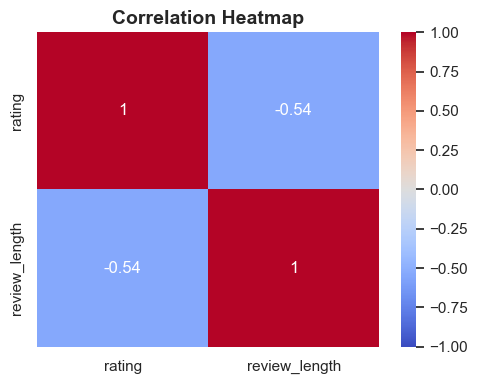

In [7]:
plt.figure(figsize=(5, 4))
sns.heatmap(df[[RATING_COL, "review_length"]].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("chart5_heatmap.png", dpi=150)
plt.show()

## Chart 6: Word cloud - most common words

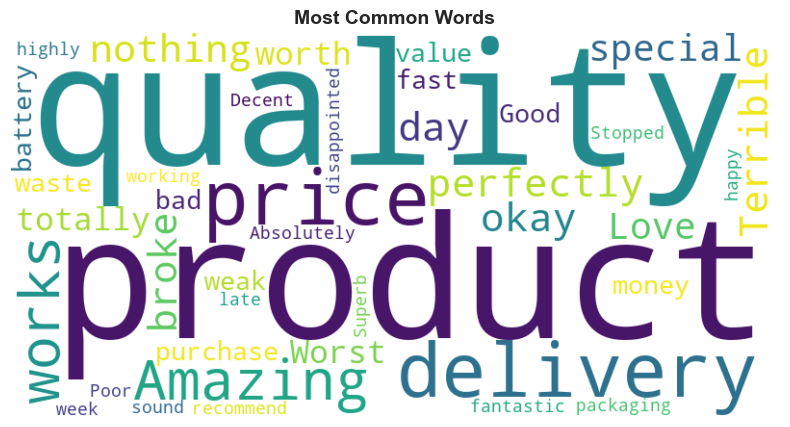

In [8]:
from wordcloud import WordCloud

wc = WordCloud(width=800, height=400, background_color="white").generate(" ".join(df[TEXT_COL]))
plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Most Common Words", fontsize=14, fontweight="bold")
plt.savefig("chart6_wordcloud.png", dpi=150)
plt.show()